### EDA and Target Binning

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set global visualization styles
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)

print("Environment setup complete.")

Environment setup complete.


Dataset Shape: (5875, 22)
Unique Patients (subject#): 42
Missing Values: 0

       motor_UPDRS  total_UPDRS
count  5875.000000  5875.000000
mean     21.296229    29.018942
std       8.129282    10.700283
min       5.037700     7.000000
25%      15.000000    21.371000
50%      20.871000    27.576000
75%      27.596500    36.399000
max      39.511000    54.992000


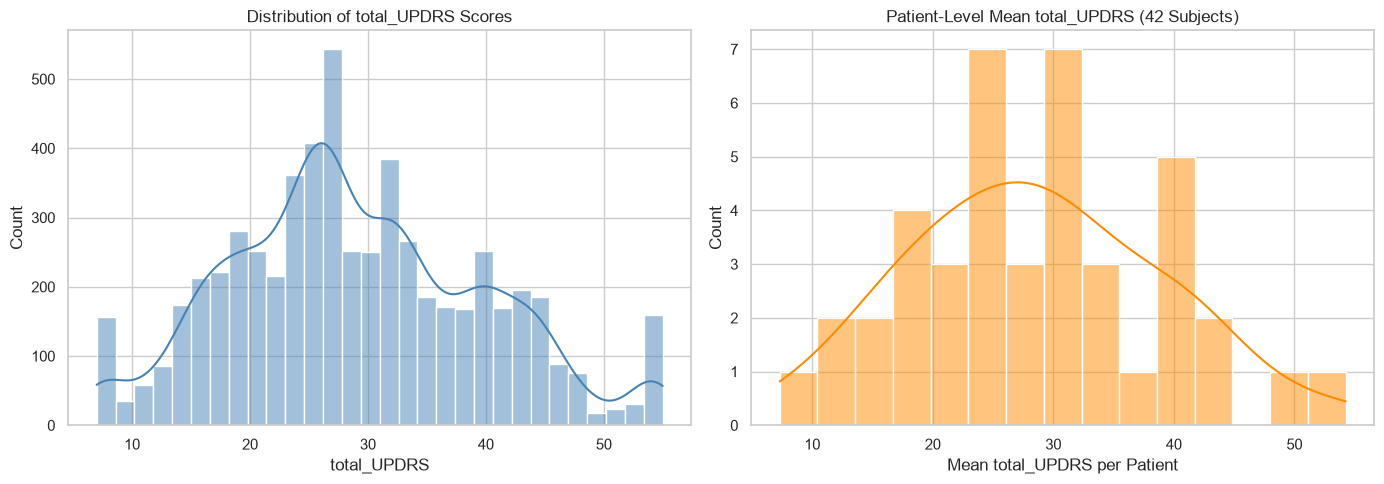

In [4]:
# Load the dataset
data_path = "../data/parkinsons_updrs.data"
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape}")
print(f"Unique Patients (subject#): {df['subject#'].nunique()}")
print(f"Missing Values: {df.isnull().sum().sum()}\n")

# Inspect summary statistics of the target variable (total_UPDRS)
print(df[['motor_UPDRS', 'total_UPDRS']].describe())

# Plot total_UPDRS distribution and candidate 3-class quantile/clinical thresholds
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['total_UPDRS'], bins=30, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title("Distribution of total_UPDRS Scores")
axes[0].set_xlabel("total_UPDRS")

# Visualize patient-level average total_UPDRS to check patient-level severity spread
patient_means = df.groupby('subject#')['total_UPDRS'].mean()
sns.histplot(patient_means, bins=15, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title("Patient-Level Mean total_UPDRS (42 Subjects)")
axes[1].set_xlabel("Mean total_UPDRS per Patient")

plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import StratifiedGroupKFold

# 1. Create 3-Class Severity Target using interpretable quantile-aligned thresholds
# Class 0 (Mild): total_UPDRS <= 24.0
# Class 1 (Moderate): 24.0 < total_UPDRS <= 34.0
# Class 2 (Severe): total_UPDRS > 34.0
bins = [0, 24.0, 34.0, 100.0]
labels = [0, 1, 2]
class_names = {0: 'Mild (<=24)', 1: 'Moderate (24-34)', 2: 'Severe (>34)'}

df['severity_class'] = pd.cut(df['total_UPDRS'], bins=bins, labels=labels).astype(int)

# 2. Verify class balance at both recording-level and patient-level
summary = pd.DataFrame({
    'Recordings': df['severity_class'].value_counts().sort_index(),
    'Share (%)': (df['severity_class'].value_counts(normalize=True).sort_index() * 100).round(1),
    'Unique Patients': df.groupby('severity_class')['subject#'].nunique()
})
summary.index = [class_names[i] for i in summary.index]
print("=== 3-Class Target Distribution ===")
print(summary, "\n")

# 3. Perform a Patient-Grouped Stratified Split (80% Train / 20% Test by Patient)
# Note: Drop motor_UPDRS, total_UPDRS, and subject# from X so the model cannot cheat
feature_cols = [c for c in df.columns if c not in ['subject#', 'motor_UPDRS', 'total_UPDRS', 'severity_class']]
X = df[feature_cols]
y = df['severity_class']
groups = df['subject#']

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_patients = set(groups.iloc[train_idx])
test_patients = set(groups.iloc[test_idx])

print("=== Leak-Free Train / Test Split Summary ===")
print(f"Train Recordings: {len(X_train)} ({len(train_patients)} patients)")
print(f"Test Recordings:  {len(X_test)} ({len(test_patients)} patients)")
print(f"Overlapping Patients: {len(train_patients.intersection(test_patients))} (Must be 0)\n")

print("Test Set Class Balance (%):")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(1).rename(index=class_names))

=== 3-Class Target Distribution ===
                  Recordings  Share (%)  Unique Patients
Mild (<=24)             1873       31.9               20
Moderate (24-34)        2226       37.9               24
Severe (>34)            1776       30.2               19 

=== Leak-Free Train / Test Split Summary ===
Train Recordings: 4636 (33 patients)
Test Recordings:  1239 (9 patients)
Overlapping Patients: 0 (Must be 0)

Test Set Class Balance (%):
severity_class
Mild (<=24)         27.6
Moderate (24-34)    44.8
Severe (>34)        27.6
Name: proportion, dtype: float64


### Baseline Modelling

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Define baseline models
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=42, eval_metric='mlogloss')
}

results = []
trained_models = {}

for name, model in models.items():
    # Train strictly on the 80% training patients
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    # Predict on the 20% unseen test patients
    y_pred = model.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    results.append({"Model": name, "Test Accuracy": round(acc, 4), "Macro F1-Score": round(macro_f1, 4)})
    
    print(f"=== {name} Classification Report ===")
    print(classification_report(y_test, y_pred, target_names=['Mild (0)', 'Moderate (1)', 'Severe (2)']))

results_df = pd.DataFrame(results).sort_values(by="Macro F1-Score", ascending=False)
print("=== Baseline Model Comparison (Unseen Test Patients) ===")
print(results_df.to_string(index=False))

=== Logistic Regression Classification Report ===
              precision    recall  f1-score   support

    Mild (0)       0.37      0.59      0.46       342
Moderate (1)       0.54      0.50      0.52       555
  Severe (2)       0.01      0.01      0.01       342

    accuracy                           0.39      1239
   macro avg       0.31      0.36      0.33      1239
weighted avg       0.35      0.39      0.36      1239

=== Random Forest Classification Report ===
              precision    recall  f1-score   support

    Mild (0)       0.45      0.65      0.54       342
Moderate (1)       0.52      0.49      0.50       555
  Severe (2)       0.05      0.04      0.04       342

    accuracy                           0.41      1239
   macro avg       0.34      0.39      0.36      1239
weighted avg       0.37      0.41      0.39      1239

=== XGBoost Classification Report ===
              precision    recall  f1-score   support

    Mild (0)       0.60      0.80      0.68       3

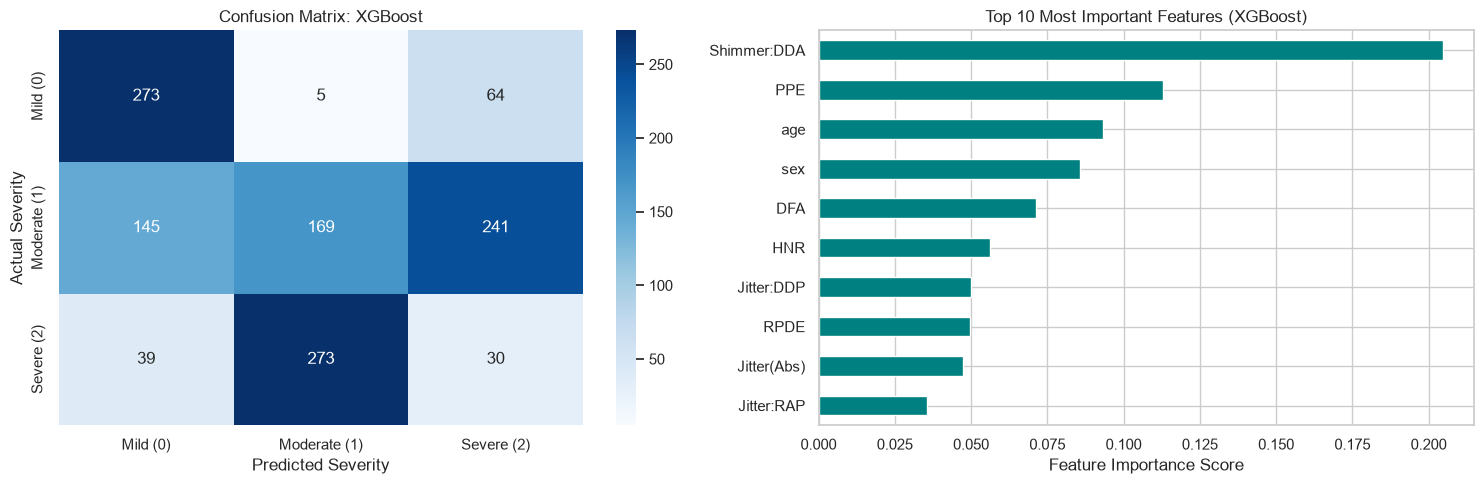

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Confusion Matrix for the top-performing model
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
cm = confusion_matrix(y_test, best_model.predict(X_test))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Mild (0)', 'Moderate (1)', 'Severe (2)'],
            yticklabels=['Mild (0)', 'Moderate (1)', 'Severe (2)'])
axes[0].set_title(f"Confusion Matrix: {best_model_name}")
axes[0].set_xlabel("Predicted Severity")
axes[0].set_ylabel("Actual Severity")

# 2. Top 10 Feature Importances (from Random Forest or XGBoost)
tree_model = trained_models["XGBoost"] if "XGBoost" in trained_models else trained_models["Random Forest"]
importances = pd.Series(tree_model.feature_importances_, index=X.columns).sort_values(ascending=True).tail(10)

importances.plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title("Top 10 Most Important Features (XGBoost)")
axes[1].set_xlabel("Feature Importance Score")

plt.tight_layout()
plt.show()

### Feature Engineering and Model Training

In [8]:
from sklearn.utils.class_weight import compute_sample_weight

# 1. Domain Feature Engineering (Row-by-row acoustic interactions — zero patient/target leakage)
df_feat = df.copy()

# Non-linear dysphonia complexity index (combines RPDE, DFA, and PPE from Little et al.)
df_feat['nonlinear_dysphonia'] = df_feat['RPDE'] * df_feat['DFA'] * df_feat['PPE']

# Joint frequency + amplitude instability (Jitter x Shimmer)
df_feat['jitter_shimmer_prod'] = df_feat['Jitter(%)'] * df_feat['Shimmer']

# Noise-to-tonal clarity ratios
df_feat['ppe_to_hnr'] = df_feat['PPE'] / (df_feat['HNR'] + 1e-5)
df_feat['nhr_to_hnr'] = df_feat['NHR'] / (df_feat['HNR'] + 1e-5)

# Long-term vs. short-term vocal perturbation ratios
df_feat['shimmer_apq_ratio'] = df_feat['Shimmer:APQ11'] / (df_feat['Shimmer:APQ3'] + 1e-6)
df_feat['jitter_ppq_rap_ratio'] = df_feat['Jitter:PPQ5'] / (df_feat['Jitter:RAP'] + 1e-6)

# Age-adjusted acoustic interactions (accounts for normal age-related vocal decline)
df_feat['age_ppe'] = df_feat['age'] * df_feat['PPE']
df_feat['age_dfa'] = df_feat['age'] * df_feat['DFA']

# Log-transform heavily skewed perturbation columns
for col in ['Jitter(%)', 'Jitter(Abs)', 'Shimmer', 'NHR']:
    df_feat[f'log_{col}'] = np.log1p(df_feat[col])

# Prepare engineered feature matrix X_eng (dropping IDs and raw UPDRS targets)
drop_cols = ['subject#', 'motor_UPDRS', 'total_UPDRS', 'severity_class']
X_eng = df_feat[[c for c in df_feat.columns if c not in drop_cols]]
y_all = df_feat['severity_class']
groups_all = df_feat['subject#']

print(f"Engineered Feature Count: {X_eng.shape[1]} features (up from {X.shape[1]} raw features)\n")

# 2. Full 5-Fold Patient-Grouped Cross-Validation with Balanced Class Weights
sgkf_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

cv_models = {
    "Logistic Regression (Balanced)": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    ),
    "Random Forest (Regularized + Balanced)": RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=15, class_weight='balanced', random_state=42, n_jobs=-1
    ),
    "XGBoost (Regularized + Balanced)": XGBClassifier(
        n_estimators=250, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8,
        reg_alpha=1.0, reg_lambda=2.0, random_state=42, eval_metric='mlogloss'
    )
}

cv_results = []
oof_preds = {}

for name, model in cv_models.items():
    preds = np.zeros(len(y_all), dtype=int)
    
    for train_idx, val_idx in sgkf_cv.split(X_eng, y_all, groups_all):
        X_tr, y_tr = X_eng.iloc[train_idx], y_all.iloc[train_idx]
        X_va = X_eng.iloc[val_idx]
        
        if "XGBoost" in name:
            weights = compute_sample_weight(class_weight='balanced', y=y_tr)
            model.fit(X_tr, y_tr, sample_weight=weights)
        else:
            model.fit(X_tr, y_tr)
            
        preds[val_idx] = model.predict(X_va)
        
    oof_preds[name] = preds
    acc = accuracy_score(y_all, preds)
    macro_f1 = f1_score(y_all, preds, average='macro')
    severe_f1 = f1_score(y_all, preds, average=None)[2]
    
    cv_results.append({
        "Model": name,
        "5-Fold Accuracy": round(acc, 4),
        "5-Fold Macro F1": round(macro_f1, 4),
        "Severe (2) F1": round(severe_f1, 4)
    })

cv_df = pd.DataFrame(cv_results).sort_values(by="5-Fold Macro F1", ascending=False)
print("=== Phase 4A: 5-Fold Cross-Validation Across All 42 Unseen Patients ===")
print(cv_df.to_string(index=False))

# Print full classification report for the best model across all 5,875 out-of-fold predictions
best_cv_name = cv_df.iloc[0]["Model"]
print(f"\n=== Detailed 5-Fold Report: {best_cv_name} ===")
print(classification_report(y_all, oof_preds[best_cv_name], target_names=['Mild (0)', 'Moderate (1)', 'Severe (2)']))

Engineered Feature Count: 31 features (up from 19 raw features)

=== Phase 4A: 5-Fold Cross-Validation Across All 42 Unseen Patients ===
                                 Model  5-Fold Accuracy  5-Fold Macro F1  Severe (2) F1
Random Forest (Regularized + Balanced)           0.3877           0.3837         0.2731
      XGBoost (Regularized + Balanced)           0.3435           0.3442         0.2327
        Logistic Regression (Balanced)           0.3425           0.3394         0.2355

=== Detailed 5-Fold Report: Random Forest (Regularized + Balanced) ===
              precision    recall  f1-score   support

    Mild (0)       0.42      0.55      0.48      1873
Moderate (1)       0.51      0.33      0.40      2226
  Severe (2)       0.26      0.29      0.27      1776

    accuracy                           0.39      5875
   macro avg       0.40      0.39      0.38      5875
weighted avg       0.40      0.39      0.39      5875



In [9]:
from sklearn.ensemble import RandomForestRegressor

# 1. Helper: Normalize key vocal features by sex strictly inside each training fold (zero leakage)
core_acoustic_cols = [
    'Jitter(%)', 'Shimmer', 'Shimmer:DDA', 'HNR', 'RPDE', 'DFA', 'PPE',
    'nonlinear_dysphonia', 'ppe_to_hnr', 'shimmer_apq_ratio'
]

def normalize_by_sex(X_tr, X_va, cols):
    X_tr_new = X_tr.copy()
    X_va_new = X_va.copy()
    for c in cols:
        X_tr_new[f'{c}_sex_z'] = 0.0
        X_va_new[f'{c}_sex_z'] = 0.0
        
    for s in [0, 1]:
        tr_mask = (X_tr_new['sex'] == s)
        va_mask = (X_va_new['sex'] == s)
        if tr_mask.sum() > 0:
            means = X_tr_new.loc[tr_mask, cols].mean()
            stds = X_tr_new.loc[tr_mask, cols].std().replace(0, 1)
            for c in cols:
                X_tr_new.loc[tr_mask, f'{c}_sex_z'] = (X_tr_new.loc[tr_mask, c] - means[c]) / stds[c]
                X_va_new.loc[va_mask, f'{c}_sex_z'] = (X_va_new.loc[va_mask, c] - means[c]) / stds[c]
                
    # Drop raw age & sex so trees cannot memorize individual patient demographics
    return X_tr_new.drop(columns=['age', 'sex']), X_va_new.drop(columns=['age', 'sex'])

# 2. Run 5-Fold Cross-Validation comparing Tuned Classification vs. Ordinal Regression-to-Bins
y_continuous = df_feat['total_UPDRS']
oof_probs_rf = np.zeros((len(y_all), 3))
oof_preds_reg = np.zeros(len(y_all), dtype=int)

for train_idx, val_idx in sgkf_cv.split(X_eng, y_all, groups_all):
    X_tr_raw, X_va_raw = X_eng.iloc[train_idx], X_eng.iloc[val_idx]
    X_tr, X_va = normalize_by_sex(X_tr_raw, X_va_raw, core_acoustic_cols)
    
    y_tr_cls = y_all.iloc[train_idx]
    y_tr_cont = y_continuous.iloc[train_idx]
    
    # Model A: Tuned Random Forest Classifier on Sex-Normalized Biomarkers
    rf_clf = RandomForestClassifier(
        n_estimators=400, max_depth=10, min_samples_leaf=10,
        max_features='sqrt', class_weight='balanced', random_state=42, n_jobs=-1
    )
    rf_clf.fit(X_tr, y_tr_cls)
    oof_probs_rf[val_idx] = rf_clf.predict_proba(X_va)
    
    # Model B: Ordinal Regression-to-Binning (learns continuous severity order, then maps to bins)
    rf_reg = RandomForestRegressor(
        n_estimators=400, max_depth=10, min_samples_leaf=10,
        max_features='sqrt', random_state=42, n_jobs=-1
    )
    rf_reg.fit(X_tr, y_tr_cont)
    cont_preds = rf_reg.predict(X_va)
    oof_preds_reg[val_idx] = pd.cut(cont_preds, bins=[0, 24.0, 34.0, 100.0], labels=[0, 1, 2]).astype(int)

oof_preds_rf = np.argmax(oof_probs_rf, axis=1)

# 3. Evaluate Session-Level Aggregation (~6 recordings taken in the same sitting)
session_df = pd.DataFrame({
    'session_id': df_feat['subject#'].astype(str) + "_" + df_feat['test_time'].round(1).astype(str),
    'actual': y_all.values,
    'prob_0': oof_probs_rf[:, 0],
    'prob_1': oof_probs_rf[:, 1],
    'prob_2': oof_probs_rf[:, 2]
})
session_agg = session_df.groupby('session_id').mean()
session_actual = session_agg['actual'].round().astype(int)
session_pred = np.argmax(session_agg[['prob_0', 'prob_1', 'prob_2']].values, axis=1)

# Compare all three evaluations
summary_4b = pd.DataFrame([
    {
        "Evaluation Level & Method": "1. Recording-Level: Tuned RF (Sex-Normalized)",
        "Accuracy": round(accuracy_score(y_all, oof_preds_rf), 4),
        "Macro F1": round(f1_score(y_all, oof_preds_rf, average='macro'), 4),
        "Severe (2) F1": round(f1_score(y_all, oof_preds_rf, average=None)[2], 4)
    },
    {
        "Evaluation Level & Method": "2. Recording-Level: Ordinal Regression-to-Bins",
        "Accuracy": round(accuracy_score(y_all, oof_preds_reg), 4),
        "Macro F1": round(f1_score(y_all, oof_preds_reg, average='macro'), 4),
        "Severe (2) F1": round(f1_score(y_all, oof_preds_reg, average=None)[2], 4)
    },
    {
        "Evaluation Level & Method": f"3. Session-Level ({len(session_agg)} Sittings): Tuned RF Avg",
        "Accuracy": round(accuracy_score(session_actual, session_pred), 4),
        "Macro F1": round(f1_score(session_actual, session_pred, average='macro'), 4),
        "Severe (2) F1": round(f1_score(session_actual, session_pred, average=None)[2], 4)
    }
])

print("=== Phase 4B: Biomarker Normalization & Clinical Session Aggregation ===")
print(summary_4b.to_string(index=False))

=== Phase 4B: Biomarker Normalization & Clinical Session Aggregation ===
                     Evaluation Level & Method  Accuracy  Macro F1  Severe (2) F1
 1. Recording-Level: Tuned RF (Sex-Normalized)    0.3317    0.3318         0.2457
2. Recording-Level: Ordinal Regression-to-Bins    0.3447    0.2737         0.0921
3. Session-Level (1030 Sittings): Tuned RF Avg    0.3214    0.3199         0.2027


### Hyperparameter tuning and Model Export

Best Hyperparameters: {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 0.3, 'max_depth': 6}

=== End-to-End Model Progression ===
                                            Stage  Accuracy  Macro F1  Severe (2) F1
Phase 3: Baseline Random Forest (19 raw features)    0.4084    0.3608         0.0400
Phase 4A: Regularized RF (31 engineered features)    0.3877    0.3837         0.2731
Phase 4C: Tuned Final RF (31 engineered features)    0.4080    0.4059         0.3236

Saved production model artifact to ../models/parkinsons_rf.joblib


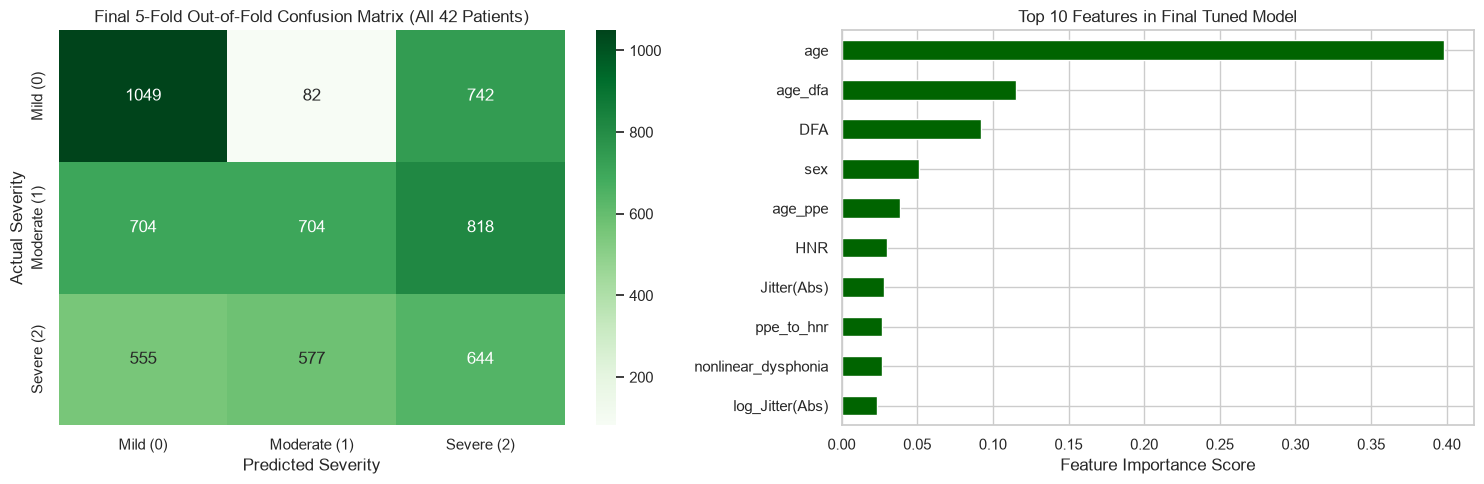

In [11]:
import os
import joblib
from sklearn.model_selection import RandomizedSearchCV

# 1. Hyperparameter Tuning on Phase 4A's 31 Engineered Features (Zero Patient Leakage)
param_dist = {
    'n_estimators': [200, 300, 500],
    'max_depth': [6, 8, 10, 12],
    'min_samples_leaf': [10, 15, 20, 25],
    'max_features': ['sqrt', 0.3, 0.5]
}

base_rf = RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1)

search = RandomizedSearchCV(
    estimator=base_rf,
    param_distributions=param_dist,
    n_iter=15,
    scoring='f1_macro',
    cv=sgkf_cv,
    random_state=42,
    n_jobs=-1
)
search.fit(X_eng, y_all, groups=groups_all)

best_rf = search.best_estimator_
print(f"Best Hyperparameters: {search.best_params_}\n")

# 2. Generate Out-of-Fold Predictions for the Tuned Model Across All 42 Patients
oof_tuned = np.zeros(len(y_all), dtype=int)
for train_idx, val_idx in sgkf_cv.split(X_eng, y_all, groups_all):
    best_rf.fit(X_eng.iloc[train_idx], y_all.iloc[train_idx])
    oof_tuned[val_idx] = best_rf.predict(X_eng.iloc[val_idx])

tuned_acc = accuracy_score(y_all, oof_tuned)
tuned_f1 = f1_score(y_all, oof_tuned, average='macro')
tuned_sev_f1 = f1_score(y_all, oof_tuned, average=None)[2]

# 3. Final Benchmark Progression Table
progression_df = pd.DataFrame([
    {"Stage": "Phase 3: Baseline Random Forest (19 raw features)", "Accuracy": 0.4084, "Macro F1": 0.3608, "Severe (2) F1": 0.0400},
    {"Stage": "Phase 4A: Regularized RF (31 engineered features)", "Accuracy": 0.3877, "Macro F1": 0.3837, "Severe (2) F1": 0.2731},
    {"Stage": "Phase 4C: Tuned Final RF (31 engineered features)", "Accuracy": round(tuned_acc, 4), "Macro F1": round(tuned_f1, 4), "Severe (2) F1": round(tuned_sev_f1, 4)}
])
print("=== End-to-End Model Progression ===")
print(progression_df.to_string(index=False))

# 4. Fit on Full Dataset (All 42 Patients) and Save Production Artifact
best_rf.fit(X_eng, y_all)
os.makedirs("../models", exist_ok=True)
artifact = {
    "model": best_rf,
    "features": list(X_eng.columns),
    "class_names": {0: "Mild (<=24)", 1: "Moderate (24-34)", 2: "Severe (>34)"},
    "cv_macro_f1": round(tuned_f1, 4)
}
joblib.dump(artifact, "../models/parkinsons_rf.joblib")
print("\nSaved production model artifact to ../models/parkinsons_rf.joblib")

# 5. Plot Final 5-Fold Confusion Matrix & Top 10 Engineered Features
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cm_final = confusion_matrix(y_all, oof_tuned)
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Greens', ax=axes[0],
            xticklabels=['Mild (0)', 'Moderate (1)', 'Severe (2)'],
            yticklabels=['Mild (0)', 'Moderate (1)', 'Severe (2)'])
axes[0].set_title("Final 5-Fold Out-of-Fold Confusion Matrix (All 42 Patients)")
axes[0].set_xlabel("Predicted Severity")
axes[0].set_ylabel("Actual Severity")

top_feats = pd.Series(best_rf.feature_importances_, index=X_eng.columns).sort_values(ascending=True).tail(10)
top_feats.plot(kind='barh', ax=axes[1], color='darkgreen')
axes[1].set_title("Top 10 Features in Final Tuned Model")
axes[1].set_xlabel("Feature Importance Score")

plt.tight_layout()
plt.show()